# Comparing the experiments

Select using 2024 validation MAE. Keep the 2025 test as a later-period check. The original LSTM scores are excluded because their evaluation was flawed.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

In [2]:
from hdb_resale.experiment import compare_runs
from hdb_resale.plots import plot_comparison

names = [
    name
    for name in ("median", "ridge", "trees", "mlp", "lstm")
    if (RUNS / name / "test.json").exists()
]
comparison = compare_runs([RUNS / name for name in names])
comparison

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\tengc\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,model,validation_mae_sgd,fit_seconds,test_count,test_mae_sgd,test_rmse_sgd,test_r2
0,mlp,27129.833145,114.869133,5414,32089.805899,44860.462164,0.948383
1,trees,36909.224815,15.199111,5414,60779.045632,73295.214445,0.862210
2,ridge,54324.963603,8.505756,5414,64631.342780,85068.028315,0.814390
3,lstm,85408.722750,845.717433,5414,98477.739152,124076.476412,0.605137
4,median,183801.932362,4.394507,5414,204699.580436,267294.318962,-0.832514


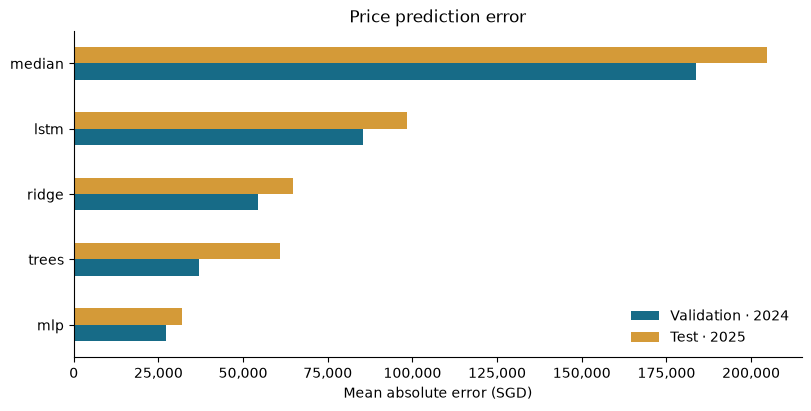

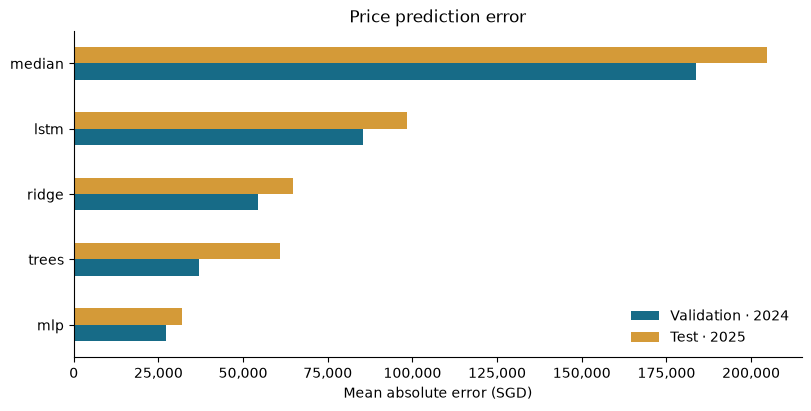

In [3]:
figure = plot_comparison(comparison)
figure

## Where does the selected model struggle?

Select the model by validation MAE, then inspect its final test errors by town. Counts prevent small groups from looking more conclusive than they are. This inspection does not trigger retuning.

In [4]:
import pandas as pd

selected_model = comparison.iloc[0]["model"]
groups = pd.read_csv(RUNS / selected_model / "test_groups.csv")
groups.loc[groups["dimension"] == "town"].sort_values("mae_sgd", ascending=False).head(
    8
)

,dimension,group,count,mae_sgd,rmse_sgd,r2
10,town,CENTRAL AREA,33,62785.741477,74659.174439,0.957103
9,town,BUKIT TIMAH,12,61079.177083,75164.895792,0.926317
24,town,SERANGOON,84,55233.586310,77807.936210,0.853164
26,town,TOA PAYOH,207,52835.437123,84239.364764,0.934502
21,town,QUEENSTOWN,145,52521.657759,73646.458942,0.941381
5,town,BISHAN,62,44578.300403,55323.862883,0.953008
17,town,KALLANG/WHAMPOA,163,42494.764379,57153.236982,0.955555
13,town,GEYLANG,142,42070.471171,54565.183773,0.949630


## Findings from the frozen snapshot

The MLP has the lowest validation MAE (S$27,130) and test MAE (S$32,090). Ridge remains a fast, useful reference. Trees improve validation error over Ridge, but their advantage narrows in 2025. The feature-sequence LSTM is slower and less accurate in this bounded run.

Choose the MLP for this historical experiment, while retaining the simpler baselines for regression checks. That selection follows validation performance; the test set supplies the final check.

These results use one split and one seed. The MLP has a 20-epoch ceiling and stopped after 14; the LSTM has a five-epoch ceiling. Unequal compute budgets limit conclusions about model families. Sparse subgroups and potentially incomplete March coverage also limit interpretation. None of these models is validated for present-day valuations.